# 1. The model

This notebook introduces the model and the two ways the package solves it: the aggregate (mean-field)
dynamical system and the agent-based simulation (DSMC). Notation follows the paper.

## Agents

Each agent holds a perceived value $v>0$ of the innovation and an adoption status: non-user ($i=1$) or user
($i=2$). The technology has price $P(t)$ and realized value $P(t)\,r(t)$; the media campaign reaches agents with
frequency $\mu_{media}(t)$ and conveys the value $P(t)\,w(t)$.

In each interaction, an agent with value $v$ meeting a partner with value $v_*$ updates as follows
(coefficients $a_1,a_2,b,c\ge0$):

| agent | update |
|---|---|
| non-user meeting a non-user | $v' = v - a_1(v-v_*) - \mu_{media}(t)\,b\,(v-Pw) + v\,\eta$ |
| non-user meeting a user | $v' = v - a_2(v-v_*) - \mu_{media}(t)\,b\,(v-Pw) + v\,\eta$ |
| user | $v' = v - c\,(v-Pr) + v\,\xi$ |

$\eta$ and $\xi$ are zero-mean self-reasoning noises with variance $\gamma b$. Media exposure acts inside each
interaction, weighted by $\mu_{media}(t)$; in the small-jump limit this is equivalent to a separate media
interaction with frequency $\mu_{media}(t)$.

**Purchases.** A non-user receives a purchase opportunity at rate $\lambda$ and adopts if $v>P$. Users never
abandon the technology.

**Realized performance.** Performance is an S-curve in cumulative investment, which depends on cumulative
expectations, adoption and an exogenous term:
$$r=\frac{r_\infty}{1+e^{-\nu(I-I_0)}},\qquad I=k_1\int_0^t m_1(s)\,ds+k_2\rho_2+\overline{I}(t),$$
where $m_1$ is the mean perceived value of non-users (the expectations) and $\rho_2$ the share of users.

## Parameters and signals in the code

`Params` holds the coefficients; `Signals` holds the exogenous functions of time. The defaults are the values
used for every figure in the paper.

Params(a1=0.01, a2=0.015, b=0.001, gam=0.8, lam=0.8, r_inf=0.8, nu=1.0, k1=0.5, k2=0.5, I0=0.0, c=1.0, xi_users=None)


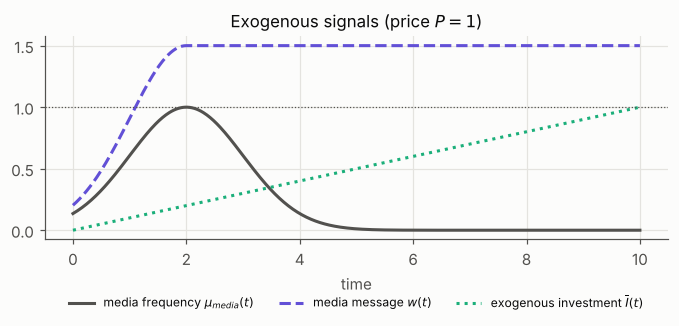

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from kinetic_hype import Params, Signals, dsmc, meanfield as mf, hype_features
from kinetic_hype.plotting import use_style, plot_trajectory, INK_2

use_style()
p, s = Params(), Signals()
print(p)

t = np.linspace(0, 10, 501)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(t, [s.media(x) for x in t], color=INK_2, label=r"media frequency $\mu_{media}(t)$")
ax.plot(t, [s.message(x) for x in t], color="#6250d6", ls="--", label=r"media message $w(t)$")
ax.plot(t, [s.investment(x) for x in t], color="#1baf7a", ls=":", label=r"exogenous investment $\overline{I}(t)$")
ax.axhline(s.price(0), color=INK_2, lw=0.8, ls=":")
ax.set_xlabel("time"); ax.set_title("Exogenous signals (price $P=1$)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, fontsize=8)
fig.tight_layout()

## The aggregate system

If perceived values relax much faster than purchases occur (time-scale separation), non-users' values sit at
the stationary state of the fast dynamics. Their mean is
$$m_1=P\,\frac{a_2\rho_2\,r+\mu_{media}\,b\,w}{a_2\rho_2+\mu_{media}\,b},$$
and their distribution is an inverse gamma,
$$\tilde f_1(v)\propto \frac{e^{-\beta/v}}{v^{2+\kappa}},\qquad
\kappa=\frac{2}{\gamma}\left(\mu_{media}+\alpha_1\rho_1+\alpha_2\rho_2\right),\qquad
\beta=\frac{2}{\gamma}\left(\alpha_1\rho_1 m_1+\alpha_2\rho_2 P r+\mu_{media} P w\right),$$
with $\alpha_i=a_i/b$ and $\rho_1=1-\rho_2$. Adoption proceeds at the rate at which non-users above the price
receive purchase opportunities:
$$\dot\rho_2=\lambda(1-\rho_2)\,G\!\left(1+\kappa,\frac{\beta}{P}\right),$$
where $G$ is the regularized lower incomplete gamma function. Together with $r$ above, this is the dynamical
system solved by `meanfield.simulate`. In the code: `mean_nonusers` is $m_1$, `stationary_density` is
$\tilde f_1$ and `adoption_hazard` is $G(1+\kappa,\beta/P)$.

peak 0.879 at t=1.68; trough 0.729 at t=4.23; adoption at t=20: 0.74


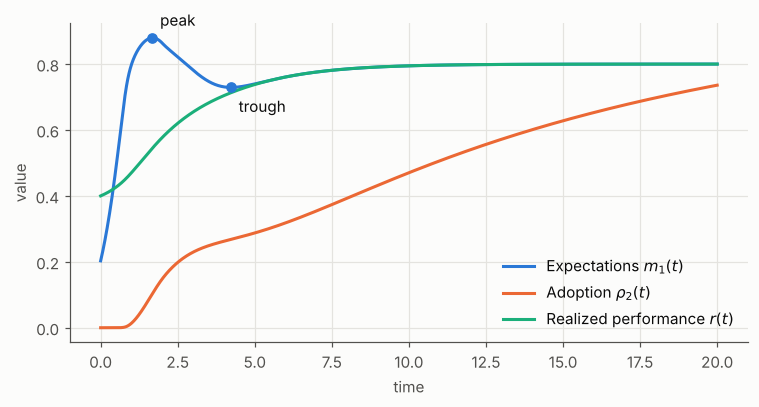

In [2]:
d = mf.simulate(p, s, T=20)
f = hype_features(d)

fig, ax = plt.subplots(figsize=(7, 3.8))
plot_trajectory(ax, d)
for t_, y_, lab, dy in [(f.t_peak, f.peak, "peak", 8), (f.t_trough, f.trough, "trough", -16)]:
    ax.plot(t_, y_, "o", color="#2a78d6", ms=6)
    ax.annotate(lab, (t_, y_), textcoords="offset points", xytext=(5, dy))
ax.set_ylabel("value"); ax.legend(loc="lower right")
fig.tight_layout()
print(f"peak {f.peak:.3f} at t={f.t_peak:.2f}; trough {f.trough:.3f} at t={f.t_trough:.2f}; "
      f"adoption at t=20: {d.rho.iloc[-1]:.2f}")

This is Figure 2 of the paper: expectations rise as the message ramps up, peak, fall when media attention
recedes faster than performance improves, and recover towards realized performance; adoption follows an
S-curve. Notebook 2 varies the inputs that shape the cycle.

The distribution of non-users' values behind these curves, at the peak and at the trough of expectations.
The area to the right of the price is the adoption hazard:

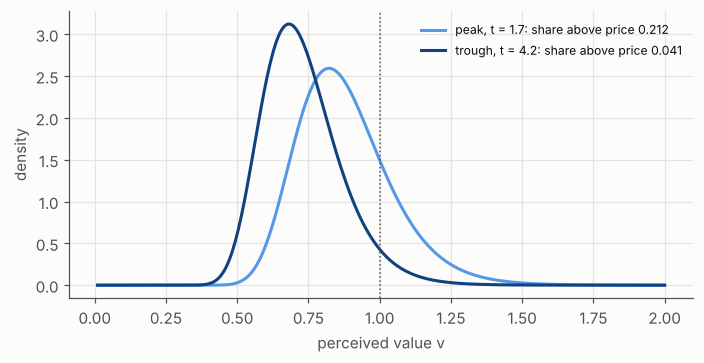

In [3]:
v = np.linspace(0.01, 2.0, 400)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for t_, c, lab in [(f.t_peak, "#5598e7", "peak"), (f.t_trough, "#104281", "trough")]:
    row = d.iloc[(d.t - t_).abs().argmin()]
    ax.plot(v, mf.stationary_density(v, row.rho, row.r, row.t, p, s), color=c,
            label=f"{lab}, t = {row.t:.1f}: share above price {mf.adoption_hazard(row.rho, row.r, row.t, p, s):.3f}")
ax.axvline(1.0, color=INK_2, ls=":", lw=1)
ax.set_xlabel("perceived value v"); ax.set_ylabel("density"); ax.legend(fontsize=8)
fig.tight_layout()

## The agent-based simulation

`dsmc.simulate` runs the interaction rules above on $N$ agents with the Nanbu–Babovsky scheme: at each step
agents are paired at random, each pair interacts with probability $\mu_c\,\Delta t$, and non-users receive
purchase opportunities with probability $\lambda\,\Delta t$. Here $\mu_c$ is the interaction rate. The aggregate
system is the limit of large $N$ and large $\mu_c$; notebook 3 shows the convergence. A short run (about
half a minute):

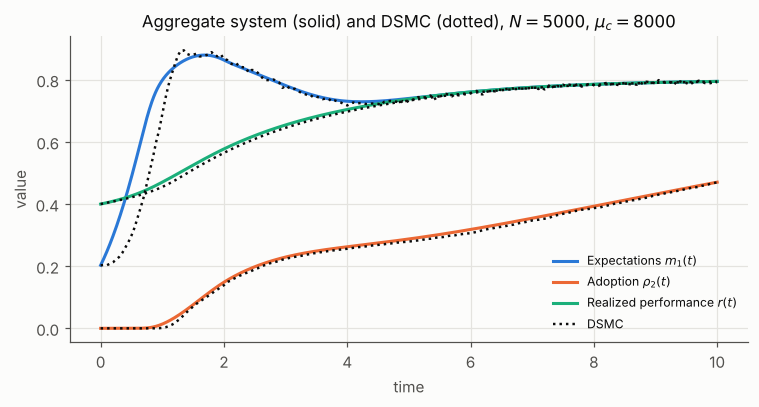

In [4]:
ab = dsmc.simulate(p, s, N=5000, mu_c=8000, T=10, seed=0)
fig, ax = plt.subplots(figsize=(7, 3.8))
plot_trajectory(ax, d[d.t <= 10], dsmc=ab)
ax.set_ylabel("value"); ax.legend(loc="lower right", fontsize=8)
ax.set_title(r"Aggregate system (solid) and DSMC (dotted), $N=5000$, $\mu_c=8000$")
fig.tight_layout()

Both functions return a table with the same columns (`t`, `rho`, `m1`, `r`, and the signals), so results
from the two solvers can be compared directly.